<a href="https://colab.research.google.com/github/namgiju/mlprog/blob/main/DL_Wine_Quality_Multiclass_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 와인 품질 분류 — 딥러닝 실습 (교수님 자료 방식)
기존 머신러닝 와인 분류를 **다중분류 딥러닝**으로 변경합니다. `X.values`, `pd.get_dummies(y).values`, `Dense(32→16→6)`, `softmax`, `categorical_crossentropy`, `SGD`를 사용합니다.

## 1. 라이브러리 불러오기

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

np.random.seed(0)
tf.keras.utils.set_random_seed(0)

## 2. 구글 드라이브 연결

In [28]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 3. CSV 불러오기
실제 파일명은 `winequality-red.csv`이며 `MyDrive` 바로 아래에 있습니다.

In [29]:
file_path = '/content/drive/MyDrive/winequality-red.csv'
df = pd.read_csv(file_path)
print('데이터 크기:', df.shape)
display(df.head())
print('품질 등급별 개수:')
print(df['quality'].value_counts().sort_index())

데이터 크기: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


품질 등급별 개수:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


## 4. X, y 나누기

In [30]:
X = df.drop(columns=['quality'])
y = df['quality']
print('입력 특성 개수:', X.shape[1])
print('품질 등급:', sorted(y.unique()))

입력 특성 개수: 11
품질 등급: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]


## 5. 원-핫 인코딩 및 NumPy 변환
교수님 자료처럼 **`Y = pd.get_dummies(y).values`**, **`X = X.values`**를 사용합니다. `quality` 3~8이 각각 6개 열로 변환됩니다.

In [31]:
class_labels = sorted(y.unique())
Y = pd.get_dummies(y).reindex(columns=class_labels, fill_value=False).values.astype(np.float32)
X = X.values.astype(np.float32)

print('X shape:', X.shape)
print('Y shape:', Y.shape)
print('첫 번째 정답:', y.iloc[0], '→ 원-핫:', Y[0])

X shape: (1599, 11)
Y shape: (1599, 6)
첫 번째 정답: 5 → 원-핫: [0. 0. 1. 0. 0. 0.]


## 6. 학습/테스트 데이터 분리 및 표준화
테스트 데이터 정보가 학습에 섞이지 않도록 학습 데이터에만 `fit_transform()`을 적용합니다.

In [32]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=0,
    stratify=y
)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)
print('학습:', X_train.shape, Y_train.shape)
print('테스트:', X_test.shape, Y_test.shape)

학습: (1279, 11) (1279, 6)
테스트: (320, 11) (320, 6)


## 7. 딥러닝 모델 생성
- 입력 특성: **11개**
- 은닉층: **Dense(32, relu) → Dense(16, relu)**
- 출력층: **Dense(6, softmax)** (6개 등급 다중분류)
- **Forward Propagation**: 입력에서 출력으로 계산합니다. `relu`가 층 사이 비선형성을 제공합니다.

In [33]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(Y_train.shape[1], activation='softmax')
])
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 32)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 6)              │           102 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,014 (3.96 KB)

 Trainable params: 1,014 (3.96 KB)

 Non-trainable params: 0 (0.00 B)

## 8. 모델 설정 — Loss Function / Optimizer
원-핫 인코딩된 다중분류이므로 `categorical_crossentropy`를 사용합니다. 최적화 방법은 교수님이 설명한 **SGD**입니다.

In [34]:
model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

## 9. 모델 학습 — 순전파 / 역전파
`fit()`에서 **순전파 → 손실 계산 → 역전파(Backward Propagation) → SGD로 가중치 업데이트**를 반복합니다.

In [35]:
history = model.fit(
    X_train, Y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2923 - loss: 1.6899 - val_accuracy: 0.4062 - val_loss: 1.6107
Epoch 2/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4154 - loss: 1.5402 - val_accuracy: 0.4688 - val_loss: 1.4811
Epoch 3/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4477 - loss: 1.4360 - val_accuracy: 0.4648 - val_loss: 1.3881
Epoch 4/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4721 - loss: 1.3612 - val_accuracy: 0.4922 - val_loss: 1.3201
Epoch 5/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4809 - loss: 1.3068 - val_accuracy: 0.4844 - val_loss: 1.2699
Epoch 6/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4946 - loss: 1.2669 - val_accuracy: 0.4961 - val_loss: 1.2323
Epoch 7/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5064 - loss: 1.2365 - val_accuracy: 0.5078 - val_loss: 1.2031
Epoch 8/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5132 - loss: 1.2125 - val_accuracy: 0.5234 - v

## 10. 테스트 데이터 평가

In [36]:
test_loss, test_acc = model.evaluate(X_test, Y_test, verbose=0)
print(f'테스트 Loss: {test_loss:.4f}')
print(f'테스트 Accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)')

테스트 Loss: 0.9293
테스트 Accuracy: 0.6187 (61.87%)


## 11. Loss / Accuracy 학습 그래프

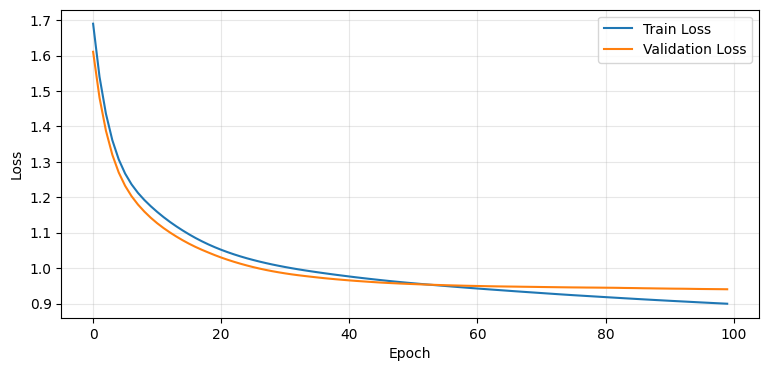

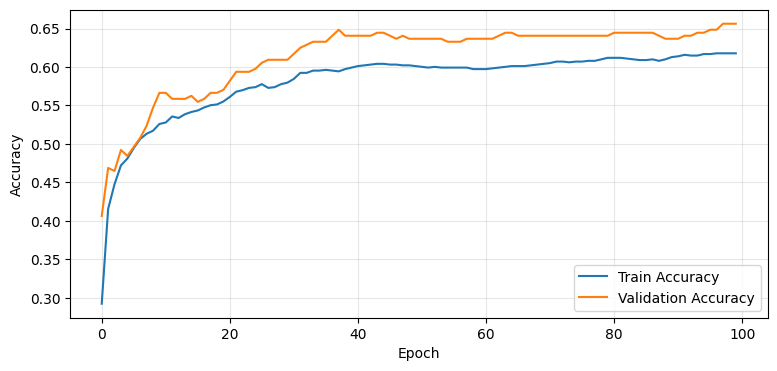

In [37]:
plt.figure(figsize=(9, 4))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.grid(alpha=0.3); plt.show()

plt.figure(figsize=(9, 4))
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.grid(alpha=0.3); plt.show()

## 12. 예측 결과 및 혼동행렬

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.68      0.79      0.73       136
           6       0.59      0.59      0.59       128
           7       0.46      0.40      0.43        40
           8       0.00      0.00      0.00         3

    accuracy                           0.62       320
   macro avg       0.29      0.30      0.29       320
weighted avg       0.58      0.62      0.60       320



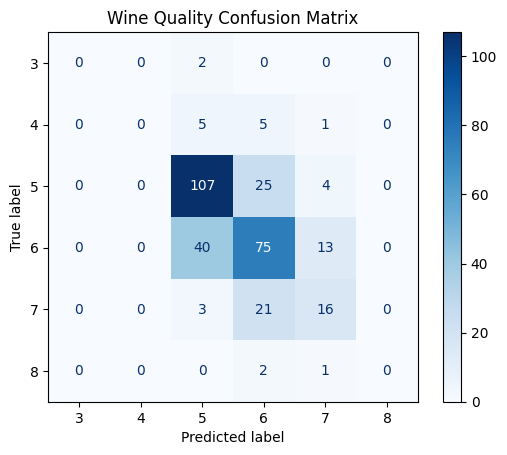

In [38]:
pred_probs = model.predict(X_test, verbose=0)
y_pred = np.array(class_labels)[np.argmax(pred_probs, axis=1)]
y_true = np.array(class_labels)[np.argmax(Y_test, axis=1)]
print(classification_report(y_true, y_pred, labels=class_labels, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=class_labels, cmap='Blues')
plt.title('Wine Quality Confusion Matrix')
plt.show()

## 13. Sparse Categorical Crossentropy 비교 (선택)
`categorical_crossentropy`는 **원-핫 벡터**, `sparse_categorical_crossentropy`는 **0부터 시작하는 정수 클래스 인덱스**를 사용합니다. **원래 품질값 3~8을 그대로 sparse 정답으로 사용하면 안 됩니다.** 아래는 정답 표현과 손실 함수의 차이만 보여줍니다.

In [26]:
Y_train_sparse = np.argmax(Y_train, axis=1)
Y_test_sparse = np.argmax(Y_test, axis=1)
print('원-핫:', Y_train[:3])
print('Sparse 정수 인덱스:', Y_train_sparse[:3])

# 새 모델을 만들어 sparse 손실함수로 학습
sparse_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(len(class_labels), activation='softmax')
])
sparse_model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
sparse_model.fit(X_train, Y_train_sparse, epochs=100, batch_size=32, validation_split=0.2, verbose=0)
print('Sparse 모델 평가:', sparse_model.evaluate(X_test, Y_test_sparse, verbose=0))

원-핫: [[0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 1. 0. 0. 0.]]
Sparse 정수 인덱스: [2 3 2]
Sparse 모델 평가: [0.9158669710159302, 0.6343749761581421]


## 정리
| 문제 유형 | 출력층 | Loss | 정답 표현 |
|---|---|---|---|
| 이진분류 | `Dense(1, sigmoid)` | `binary_crossentropy` | 0/1 |
| 다중분류 (원-핫) | `Dense(클래스 수, softmax)` | `categorical_crossentropy` | 원-핫 |
| 다중분류 (정수 인덱스) | `Dense(클래스 수, softmax)` | `sparse_categorical_crossentropy` | 0~클래스 수-1 |
| 회귀 | `Dense(1)` | `mse` | 연속값 |

**참고:** 와인 등급별 데이터 수가 불균형하므로 정확도뿐 아니라 혼동행렬과 클래스별 재현율도 확인합니다.